# Redes Neuronales Recurrentes (RNN)

En este notebook vamos a implementar una modelo de lenguaje a nivel carácter sobre *Tiny Shakespeare*: en cada posición de la secuencia, predecir el próximo carácter.

```
many-to-many (sincronizado)
       ŷ1   ŷ2   ŷ3   ŷ4
        ↑    ↑   ↑    ↑
h0 →  [h1]→[h2]→[h3]→[h4]
       ↑    ↑    ↑    ↑               
       x1   x2   x3   x4               
```

### Notación de dimensiones (la usamos en todo el notebook)

| Símbolo | Significado | Parámetro de PyTorch |
|---|---|---|
| `B` | tamaño del batch | — |
| `T` | largo de la secuencia (pasos de tiempo) | — |
| `D` | *features* por paso de tiempo | `input_size` |
| `H` | tamaño del estado oculto | `hidden_size` |
| `L` | cantidad de capas recurrentes apiladas | `num_layers` |
| `V` | tamaño del vocabulario (problema de texto) | — |
| `E` | dimensión del *embedding* | `embedding_dim` |

Importamos lo necesario para trabajar con este notebook.

In [84]:
import copy, math, time, urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.11.0+cu130 | device: cuda


---
# 1. Anatomía de una RNN

Una RNN "simple" aplica **la misma** función en cada paso de tiempo `t`:

$$
h_t = \tanh\left(x_t U_{ih}^\top + b_{ih} + h_{t-1} W_{hh}^\top + b_{hh}\right)
$$

Con dimensiones (para un batch):

| Tensor | Forma | Comentario |
|---|---|---|
| $x_t$ | `(B, D)` | entrada en el paso `t` |
| $h_{t-1}, h_t$ | `(B, H)` | estado oculto ("memoria") |
| $U_{ih}$ | `(H, D)` | proyecta la entrada al espacio oculto |
| $W_{hh}$ | `(H, H)` | proyecta el estado anterior |
| $b_{ih}, b_{hh}$ | `(H,)` | sesgos (se suman por *broadcasting*) |

Punto clave: **los pesos se comparten entre todos los pasos de tiempo**, por eso la cantidad de parámetros **no depende de `T`**.

In [85]:
B, T, D, H = 4, 6, 3, 5  # batch, pasos, features, hidden
rnn = nn.RNN(input_size=D, hidden_size=H, num_layers=1, batch_first=True) # Notar que no le digo los instantes de tiempo a la RNN!

for name, p in rnn.named_parameters():
    print(f"{name:14s} {str(tuple(p.shape)):10s}")

n_params = sum(p.numel() for p in rnn.parameters())
print(f"\nTotal de parámetros: {n_params}  =  H*D + H*H + 2*H  =  {H*D} + {H*H} + {2*H}")

weight_ih_l0   (5, 3)    
weight_hh_l0   (5, 5)    
bias_ih_l0     (5,)      
bias_hh_l0     (5,)      

Total de parámetros: 50  =  H*D + H*H + 2*H  =  15 + 25 + 10


### ¿Qué devuelve `nn.RNN`?

`out, h_n = rnn(x, h0)`

In [86]:
x  = torch.randn(B, T, D) # Le pasamos 4 instancias de tamaño T, D. Pensemos un ejemplo en el pizarrón! :D
h0 = torch.zeros(1, B, H) # -> si no lo pasás, PyTorch usa ceros

print("x   :", tuple(x.shape),   " (B, T, D)")
print("h0  :", tuple(h0.shape),  " (L, B, H)")

x   : (4, 6, 3)  (B, T, D)
h0  : (1, 4, 5)  (L, B, H)


In [87]:
out, h_n = rnn(x, h0)

In [88]:
print("out :", tuple(out.shape), " (B, T, H)  -> última capa, todos los pasos") # La representacion que obtenemos en la última capa, lo importante acá son los T y H

out : (4, 6, 5)  (B, T, H)  -> última capa, todos los pasos


In [89]:
print("h_n :", tuple(h_n.shape), " (L, B, H)  -> todas las capas, último paso")

print("\n¿out[:, -1, :] == h_n[-1]?", torch.allclose(out[:, -1, :], h_n[-1]))

# De todas las capas el último paso, desapareció T :O

h_n : (1, 4, 5)  (L, B, H)  -> todas las capas, último paso

¿out[:, -1, :] == h_n[-1]? True


### Capas apiladas y bidireccionalidad

Lo que vimos hasta recién es teniendo solo una capa de RNN, qué pasa si tenemos más? Con `num_layers=2`, la capa 2 recibe como entrada la secuencia `out` de la capa 1, así que su `weight_ih_l1` tiene forma `(H, H)` en lugar de `(H, D)`.

In [90]:
r = nn.RNN(D, H, num_layers=1, batch_first=True)
o, hn = r(x)
print(f"L={1} | out {str(tuple(o.shape)):12s} = (B, T, H)"
      f" | h_n {str(tuple(hn.shape)):12s} = (L, B, H)")

L=1 | out (4, 6, 5)    = (B, T, H) | h_n (1, 4, 5)    = (L, B, H)


In [91]:
for p in r.named_parameters():
   print(p)

('weight_ih_l0', Parameter containing:
tensor([[ 0.1280, -0.0977,  0.1741],
        [-0.3670,  0.3320, -0.3283],
        [-0.0772,  0.0934,  0.2309],
        [ 0.3610,  0.4074, -0.3546],
        [ 0.1125, -0.1924, -0.0490]], requires_grad=True))
('weight_hh_l0', Parameter containing:
tensor([[-0.3347,  0.4073, -0.3282,  0.2390,  0.1572],
        [ 0.1453, -0.2418,  0.4065,  0.0983,  0.0575],
        [-0.3941,  0.1877, -0.0671, -0.2049,  0.3841],
        [ 0.0997, -0.2474, -0.2264, -0.0214,  0.2497],
        [-0.1143, -0.2552, -0.1531, -0.3341,  0.1595]], requires_grad=True))
('bias_ih_l0', Parameter containing:
tensor([ 0.3462, -0.4210,  0.1039,  0.2310,  0.0811], requires_grad=True))
('bias_hh_l0', Parameter containing:
tensor([-0.1593,  0.2334,  0.2350,  0.1672, -0.0786], requires_grad=True))


In [92]:
r = nn.RNN(D, H, num_layers=2, batch_first=True)
o, hn = r(x)
print(f"L={2} | out {str(tuple(o.shape)):12s} = (B, T, H)"
      f" | h_n {str(tuple(hn.shape)):12s} = (L, B, H)")

L=2 | out (4, 6, 5)    = (B, T, H) | h_n (2, 4, 5)    = (L, B, H)


In [93]:
for p in r.named_parameters():
   print(p)

('weight_ih_l0', Parameter containing:
tensor([[-0.1184,  0.0478, -0.0790],
        [-0.1333,  0.2859,  0.3843],
        [-0.0443, -0.1001,  0.0065],
        [-0.0267,  0.1075,  0.1253],
        [-0.4062, -0.1650,  0.3766]], requires_grad=True))
('weight_hh_l0', Parameter containing:
tensor([[ 0.1742, -0.0222, -0.2696, -0.2736, -0.4006],
        [-0.1458,  0.1510,  0.2852,  0.2065, -0.3953],
        [-0.2689, -0.0706,  0.4326,  0.0647, -0.1158],
        [ 0.1850, -0.1703, -0.2895,  0.3264, -0.2033],
        [-0.0897, -0.4449,  0.2993,  0.3388,  0.1630]], requires_grad=True))
('bias_ih_l0', Parameter containing:
tensor([-0.3118, -0.4414, -0.3632,  0.3335,  0.2147], requires_grad=True))
('bias_hh_l0', Parameter containing:
tensor([ 0.3763,  0.2343,  0.1132, -0.0044, -0.3401], requires_grad=True))
('weight_ih_l1', Parameter containing:
tensor([[-0.3832, -0.4183,  0.1831, -0.2196, -0.0900],
        [-0.2574, -0.0815, -0.3148, -0.2922,  0.1483],
        [-0.1329,  0.2761, -0.1435, -0.3281, 

In [94]:
print("\nParámetros de una RNN de 2 capas:")
for name, p in nn.RNN(D, H, num_layers=2, batch_first=True).named_parameters():
    print(f"  {name:14s} {tuple(p.shape)}")


Parámetros de una RNN de 2 capas:
  weight_ih_l0   (5, 3)
  weight_hh_l0   (5, 5)
  bias_ih_l0     (5,)
  bias_hh_l0     (5,)
  weight_ih_l1   (5, 5)
  weight_hh_l1   (5, 5)
  bias_ih_l1     (5,)
  bias_hh_l1     (5,)


¿Qué sucede si queremos aplicar bidireccionalidad? `bidirectional=True` hay una segunda RNN que recorre la secuencia al revés; sus salidas se **concatenan** en la última dimensión (`2*H`).

In [95]:
r = nn.RNN(D, H, num_layers=1, bidirectional=True, batch_first=True)
o, hn = r(x)
print(f"L={1} bidir=Sí | out {str(tuple(o.shape)):12s} = (B, T, 2*H)"
      f" | h_n {str(tuple(hn.shape)):12s} = (L*2, B, H)")

L=1 bidir=Sí | out (4, 6, 10)   = (B, T, 2*H) | h_n (2, 4, 5)    = (L*2, B, H)


In [96]:
print("\nParámetros de una RNN de 1 capas:")
for name, p in nn.RNN(D, H, num_layers=1, bidirectional=True, batch_first=True).named_parameters():
    print(f"  {name:14s} {tuple(p.shape)}")


Parámetros de una RNN de 1 capas:
  weight_ih_l0   (5, 3)
  weight_hh_l0   (5, 5)
  bias_ih_l0     (5,)
  bias_hh_l0     (5,)
  weight_ih_l0_reverse (5, 3)
  weight_hh_l0_reverse (5, 5)
  bias_ih_l0_reverse (5,)
  bias_hh_l0_reverse (5,)


Pueden probar como queda para 2 capas y bidireccional!

### Del `out` a cada tipo de problema

La "cabeza" que va después de la RNN es lo único que cambia:

* **many-to-one**: nos quedamos con el último paso, `out[:, -1, :]` → `(B, H)` → `Linear(H, K)` → `(B, K)`.
* **many-to-many**: usamos `out` completo `(B, T, H)` → `Linear(H, K)` → `(B, T, K)`.

`nn.Linear` opera sobre **la última dimensión** y trata a todas las anteriores como "batch", así que se aplica a cada paso de tiempo sin escribir ningún bucle (con los mismos pesos en todos los pasos).

In [97]:
print("out :", tuple(out.shape), " (B, T, H)  -> última capa, todos los pasos") # La representacion que obtenemos en la última capa, lo importante acá son los T y H

out : (4, 6, 5)  (B, T, H)  -> última capa, todos los pasos


In [98]:
cabeza = nn.Linear(H, 2)
print("many-to-one :", tuple(out[:, -1, :].shape), "->", tuple(cabeza(out[:, -1, :]).shape)) # Se lo puedo aplicar a un instante de tiempo
print("many-to-many:", tuple(out.shape), "->", tuple(cabeza(out).shape)) # O a TODOS :DDDDD

many-to-one : (4, 5) -> (4, 2)
many-to-many: (4, 6, 5) -> (4, 6, 2)


---
# 2. Many-to-many: modelo de lenguaje a nivel carácter

**Dataset:** *Tiny Shakespeare* (~1.1 millones de caracteres de obras de Shakespeare), el corpus que popularizó Andrej Karpathy con `char-rnn`.

**Tarea:** para una secuencia de `T` caracteres, predecir **en cada posición** el carácter siguiente. Entrada y salida tienen el mismo largo: es un many-to-many **sincronizado**.
```
entrada  x:  F  i  r  s  t  ␣  C  i
objetivo y:  i  r  s  t  ␣  C  i  t      (la misma secuencia corrida un lugar)
```

In [99]:
URL_SHAKES = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
texto = urllib.request.urlopen(URL_SHAKES).read().decode("utf-8")
print(f"{len(texto):,} caracteres\n")
print(texto[:300])

1,115,394 caracteres

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us


### 2.1 Vocabulario y codificación

Cada carácter distinto recibe un índice entero. Las redes no reciben letras sino estos índices (tensores `long`).

In [100]:
# Acá estamos definiendo nuestro vocabulario

chars = sorted(set(texto))
V = len(chars)
stoi = {c: i for i, c in enumerate(chars)}
itos = {i: c for c, i in stoi.items()}
encode = lambda s: [stoi[c] for c in s]
decode = lambda ids: "".join(itos[i] for i in ids)

print("V =", V)
print("vocabulario:", repr("".join(chars)))
print("encode('Hola') ->", encode("Hola"), "-> decode ->", decode(encode("Hola")))

V = 65
vocabulario: "\n !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"
encode('Hola') -> [20, 53, 50, 39] -> decode -> Hola


In [101]:
itos

{0: '\n',
 1: ' ',
 2: '!',
 3: '$',
 4: '&',
 5: "'",
 6: ',',
 7: '-',
 8: '.',
 9: '3',
 10: ':',
 11: ';',
 12: '?',
 13: 'A',
 14: 'B',
 15: 'C',
 16: 'D',
 17: 'E',
 18: 'F',
 19: 'G',
 20: 'H',
 21: 'I',
 22: 'J',
 23: 'K',
 24: 'L',
 25: 'M',
 26: 'N',
 27: 'O',
 28: 'P',
 29: 'Q',
 30: 'R',
 31: 'S',
 32: 'T',
 33: 'U',
 34: 'V',
 35: 'W',
 36: 'X',
 37: 'Y',
 38: 'Z',
 39: 'a',
 40: 'b',
 41: 'c',
 42: 'd',
 43: 'e',
 44: 'f',
 45: 'g',
 46: 'h',
 47: 'i',
 48: 'j',
 49: 'k',
 50: 'l',
 51: 'm',
 52: 'n',
 53: 'o',
 54: 'p',
 55: 'q',
 56: 'r',
 57: 's',
 58: 't',
 59: 'u',
 60: 'v',
 61: 'w',
 62: 'x',
 63: 'y',
 64: 'z'}

In [102]:
datos = torch.tensor(encode(texto), dtype=torch.long)       # (1_115_394,)
n_tr = int(0.9 * len(datos))
datos_train, datos_val = datos[:n_tr], datos[n_tr:]
print("datos:", tuple(datos.shape), datos.dtype, "| train", len(datos_train), "| val", len(datos_val))

datos: (1115394,) torch.int64 | train 1003854 | val 111540


In [103]:
datos_train

tensor([18, 47, 56,  ..., 43, 56, 43])

### 2.2 Armado de batches

Elegimos `B` posiciones al azar en el texto y cortamos `T` caracteres para `x` y los mismos `T` corridos un lugar para `y`.

* `x`: `(B, T)` de tipo `long`, índices. Todavía **no** tiene dimensión de features: la va a agregar el *embedding*.
* `y`: `(B, T)` de tipo `long`, un objetivo **por cada paso**.

In [104]:
T_SEQ, B_SEQ = 100, 64 # Elijo de a cuántos voy a predecir y cuántas secuencias van a estar en el batch

def get_batch(split, B=B_SEQ, T=T_SEQ):
    d = datos_train if split == "train" else datos_val
    ini = torch.randint(len(d) - T - 1, (B,)) # Selecciona las B posiciones al azar
    x = torch.stack([d[i:i + T]         for i in ini])    # (B, T)
    y = torch.stack([d[i + 1:i + T + 1] for i in ini])    # (B, T) corrido uno!
    return x.to(device), y.to(device)

xb, yb = get_batch("train")
print("x:", tuple(xb.shape), xb.dtype, "| y:", tuple(yb.shape), yb.dtype)
print("\nPrimeros 10 pasos de la muestra 0 (entrada -> objetivo):")
for t in range(10):
    print(f"  t={t}: {itos[xb[0, t].item()]!r:6} -> {itos[yb[0, t].item()]!r}")

x: (64, 100) torch.int64 | y: (64, 100) torch.int64

Primeros 10 pasos de la muestra 0 (entrada -> objetivo):
  t=0: 'a'    -> 'r'
  t=1: 'r'    -> 'd'
  t=2: 'd'    -> ' '
  t=3: ' '    -> 'a'
  t=4: 'a'    -> 'n'
  t=5: 'n'    -> 'd'
  t=6: 'd'    -> ' '
  t=7: ' '    -> 'a'
  t=8: 'a'    -> ' '
  t=9: ' '    -> 'v'


### 2.3 Embedding: de índices a vectores

`nn.Embedding(V, E)` es una tabla de `V` filas por `E` columnas, y el índice `i` selecciona la fila `i`. Es **matemáticamente idéntico** a hacer *one-hot* (vector de largo `V`) y multiplicarlo por una matriz `(V, E)`, pero sin construir los vectores one-hot.

In [105]:
# Queremos aprender una representación de los caracteres, podríamos agarrar un modelo preentrenado acá
E = 128
emb = nn.Embedding(V, E).to(device)

print("emb.weight:", tuple(emb.weight.shape), "(V, E)")

emb.weight: (65, 128) (V, E)


### 2.4 El modelo many-to-many

```
x (B, T) ─Embedding─► (B, T, E) ─RNN (L capas)─► out (B, T, H) ─Linear─► logits (B, T, V)
```

La diferencia con many-to-one está en una sola línea: **no** nos quedamos con `out[:, -1]`, aplicamos la cabeza a todos los pasos.

El `forward` también devuelve `h_n`, que vamos a necesitar para **generar texto** (para continuar la secuencia a partir de donde quedó).

In [125]:
class CharRNN(nn.Module):
    def __init__(self, V, E=128, H=256, L=2, dropout=0.2):
        super().__init__()
        self.emb  = nn.Embedding(V, E)
        self.rnn  = nn.RNN(E, H, num_layers=L, batch_first=True, dropout=dropout)
        self.head = nn.Linear(H, V) # La quiero llevar al tamaño del vocabulario para después predecir!

    def forward(self, idx, h0=None, verbose=False):
        x = self.emb(idx)                  # (B, T)    -> (B, T, E)
        out, h_n = self.rnn(x, h0)         # (B, T, E) -> (B, T, H) ; h_n (L, B, H) # todos los ultimos estados ocultos y el ultimo estado oculto de todas las capas
        logits = self.head(out)            # (B, T, H) -> (B, T, V)
        if verbose:
            print(f"idx      : {tuple(idx.shape)}            (B, T)")
            print(f"embedding: {tuple(x.shape)}        (B, T, E)")
            print(f"out RNN  : {tuple(out.shape)}       (B, T, H)")
            print(f"h_n      : {tuple(h_n.shape)}         (L, B, H)")
            print(f"logits   : {tuple(logits.shape)}        (B, T, V)")
        return logits, h_n

Puede ser bidireccional?

In [126]:
torch.manual_seed(0)
char_rnn = CharRNN(V).to(device)
logits, _ = char_rnn(xb, verbose=True)

print()
for name, p in char_rnn.named_parameters():
    print(f"{name:20s} {tuple(p.shape)}")
print("Total parámetros:", f"{sum(p.numel() for p in char_rnn.parameters()):,}")

idx      : (64, 100)            (B, T)
embedding: (64, 100, 128)        (B, T, E)
out RNN  : (64, 100, 256)       (B, T, H)
h_n      : (2, 64, 256)         (L, B, H)
logits   : (64, 100, 65)        (B, T, V)

emb.weight           (65, 128)
rnn.weight_ih_l0     (256, 128)
rnn.weight_hh_l0     (256, 256)
rnn.bias_ih_l0       (256,)
rnn.bias_hh_l0       (256,)
rnn.weight_ih_l1     (256, 256)
rnn.weight_hh_l1     (256, 256)
rnn.bias_ih_l1       (256,)
rnn.bias_hh_l1       (256,)
head.weight          (65, 256)
head.bias            (65,)
Total parámetros: 255,425


### 2.5 La pérdida: aplanar `(B, T, V)` → `(B·T, V)`

`nn.CrossEntropyLoss` espera los logits como `(N, C)` y los objetivos como `(N,)` con enteros. Tenemos `B·T` predicciones independientes de una clase entre `V`, así que **aplanamos batch y tiempo**:

* logits `(B, T, V)` → `(B*T, V)`
* objetivos `(B, T)` → `(B*T,)`

La pérdida resultante es el promedio sobre **todas las posiciones de todas las secuencias**.

Con pesos aleatorios, el modelo predice algo cercano a uniforme sobre `V` clases, así que la pérdida inicial debería estar cerca de $\ln V$.


In [80]:
logits.shape

torch.Size([64, 100, 65])

In [83]:
ce = nn.CrossEntropyLoss()
Bq, Tq, Vq = logits.shape
loss_a = ce(logits.reshape(Bq * Tq, Vq), yb.reshape(Bq * Tq))   # (6400, V) y (6400,)
loss_b = ce(logits.transpose(1, 2), yb)                         # (B, V, T) y (B, T)

print("logits aplanados :", (Bq * Tq, Vq), "| objetivos aplanados:", (Bq * Tq,))
print(f"loss (reshape)   : {loss_a.item():.4f}")
print(f"loss (transpose) : {loss_b.item():.4f}")
print(f"ln(V)            : {math.log(V):.4f}  <- valor esperado al inicio")

logits aplanados : (6400, 65) | objetivos aplanados: (6400,)
loss (reshape)   : 4.1928
loss (transpose) : 4.1928
ln(V)            : 4.1744  <- valor esperado al inicio


### 2.6 Entrenamiento

**Cada paso de tiempo aporta un término a la pérdida**. En BPTT, el gradiente que llega a $h_t$ tiene dos fuentes: el error de la predicción en `t` y lo que viene "desde el futuro" a través de $h_{t+1}$.

Durante el entrenamiento la entrada en cada paso es el carácter **real** anterior, no el que predijo el modelo. Esto se llama *teacher forcing* y es lo que permite procesar los `T` pasos en paralelo en un solo `forward`.

Usamos *truncated BPTT*: cada secuencia de 100 caracteres es independiente y el gradiente no se propaga más allá de esos 100 pasos.

In [127]:
@torch.no_grad()
def estimar_loss(model, n_batches=20):
    model.eval()
    res = {}
    for split in ["train", "val"]:
        ls = []
        for _ in range(n_batches):
            x, y = get_batch(split)
            lg, _ = model(x)
            ls.append(ce(lg.reshape(-1, V), y.reshape(-1)).item())
        res[split] = float(np.mean(ls))
    model.train()
    return res

In [128]:
torch.manual_seed(0)
char_rnn = CharRNN(V, E=128, H=256, L=2, dropout=0.2).to(device)
opt = torch.optim.Adam(char_rnn.parameters(), lr=2e-3)

In [129]:
PASOS, CADA = 2500, 250
hist_c = {"paso": [], "train": [], "val": []}
t0 = time.time()
char_rnn.train()
for paso in range(PASOS + 1):
    if paso % CADA == 0:
        l = estimar_loss(char_rnn)
        hist_c["paso"].append(paso); hist_c["train"].append(l["train"]); hist_c["val"].append(l["val"])
        print(f"paso {paso:5d} | loss train {l['train']:.3f} | loss val {l['val']:.3f} | {time.time() - t0:5.0f} s")
    if paso == PASOS:
        break
    x, y = get_batch("train")                    # (B, T), (B, T)
    logits, _ = char_rnn(x, verbose=False)       # (B, T, V)  # Tiramos el último estado oculto solo (para inferencia vamos a querer eso)
    loss = ce(logits.reshape(-1, V), y.reshape(-1))
    opt.zero_grad()
    loss.backward()
    nn.utils.clip_grad_norm_(char_rnn.parameters(), 1.0)
    opt.step()

paso     0 | loss train 4.190 | loss val 4.187 |     0 s
paso   250 | loss train 1.673 | loss val 1.795 |     2 s
paso   500 | loss train 1.516 | loss val 1.691 |     3 s
paso   750 | loss train 1.481 | loss val 1.648 |     5 s
paso  1000 | loss train 1.438 | loss val 1.612 |     6 s
paso  1250 | loss train 1.413 | loss val 1.613 |     8 s
paso  1500 | loss train 1.406 | loss val 1.610 |    10 s
paso  1750 | loss train 1.390 | loss val 1.593 |    11 s
paso  2000 | loss train 1.380 | loss val 1.591 |    13 s
paso  2250 | loss train 1.372 | loss val 1.584 |    14 s
paso  2500 | loss train 1.375 | loss val 1.585 |    16 s


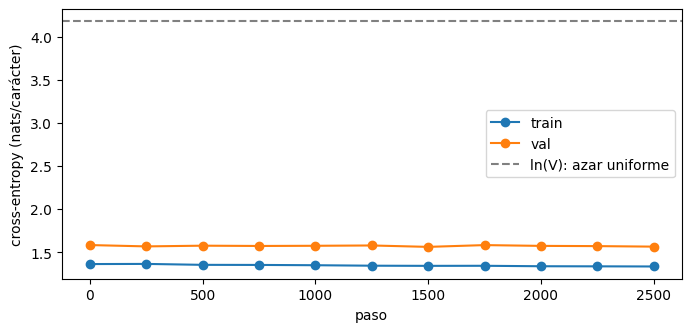

In [114]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(hist_c["paso"], hist_c["train"], "o-", label="train")
ax.plot(hist_c["paso"], hist_c["val"], "o-", label="val")
ax.axhline(math.log(V), ls="--", c="gray", label="ln(V): azar uniforme")
ax.set_xlabel("paso"); ax.set_ylabel("cross-entropy (nats/carácter)"); ax.legend()
plt.show()

### 2.7 Generación: de many-to-many a "un paso a la vez"

Para generar no tenemos el texto real, así que el modelo se alimenta con **su propia predicción**:

1. Pasamos un texto inicial (*prompt*) completo para "calentar" el estado oculto: `(1, T0)` → logits `(1, T0, V)`, `h` `(L, 1, H)`.
2. Tomamos los logits del último paso `(1, V)`, los dividimos por una *temperatura*, aplicamos *softmax* y muestreamos un carácter `(1, 1)`.
3. Volvemos a llamar al modelo con **solo ese carácter** `(1, 1)` **y el estado `h`** anterior. Así la RNN sigue "recordando" todo lo previo sin reprocesarlo.

Temperatura baja → texto más conservador y repetitivo. Temperatura alta → más creativo y con más errores.

In [130]:
@torch.no_grad()
def generar(model, inicio="ROMEO:\n", n=400, temperatura=0.1, verbose=False):
    model.eval()
    idx = torch.tensor([encode(inicio)], device=device)            # (1, T0)
    logits, h = model(idx)                                         # (1, T0, V), (L, 1, H)
    salida = list(inicio)
    for paso in range(n):
        probs = torch.softmax(logits[:, -1, :] / temperatura, -1)  # (1, V)
        sig = torch.multinomial(probs, num_samples=1)              # (1, 1) hace un sorteo donde cada índice tiene la chance que indica su probabilidad
        if verbose and paso == 0:
            print(f"idx {tuple(idx.shape)} -> logits {tuple(logits.shape)}, h {tuple(h.shape)}")
            print(f"probs {tuple(probs.shape)} -> siguiente {tuple(sig.shape)}")
        salida.append(itos[sig.item()]) # Agregamos lo que predijo recién
        logits, h = model(sig, h)       # Ahora pasamos el nuevo id predicho y el estado oculto (1, 1) -> (1, 1, V)
    return "".join(salida)

torch.manual_seed(1)
print(generar(char_rnn, n=1, verbose=True))

idx (1, 7) -> logits (1, 7, 65), h (2, 1, 256)
probs (1, 65) -> siguiente (1, 1)
ROMEO:
I


In [131]:
for temp in [0.4, 1.2]:
    torch.manual_seed(2)
    print(f"===== temperatura {temp} =====")
    print(generar(char_rnn, inicio="KING:\n", n=100, temperatura=temp, verbose=False), "\n")

===== temperatura 0.4 =====
KING:
I would be a true to the time of the common of the seat and friends, this send the boy.

Second Serv 

===== temperatura 1.2 =====
KING:
Content, coath'd again;
This hour?

MERCUTIO:
Thus seems? lay; say, it is between to be use part.
th 

